# Held-out biological distribution reconstruction

Remove **E15.5** from the paired pancreas snapshots, train on **E14.5 and E16.5** for **1,000 vector-field iterations**, and reconstruct the missing distribution at its original time.

Both the FiLM map **T** and the vector field use only the retained stages. This notebook uses the existing, frozen RNA PCA50 / ATAC PoissonVI22 representations and normalization; it is a temporal holdout in that representation, rather than an end-to-end raw-data holdout. Balanced mode compares probability distributions, not absolute cell counts.

Install the notebook and visualization extras with `python -m pip install -e '.[notebooks,visualization]'`. The paired reduced inputs are available in [TraInfBench](https://github.com/shankswang953/TraInfBench/tree/main/data/processed/pancreas). Set `COATI_BIO_DATA` to their directory if TraInfBench is not a sibling checkout.

In [1]:
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ[key] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/coati-matplotlib")
os.environ.setdefault("NUMBA_CACHE_DIR", "/private/tmp/coati-numba")

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import time

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from geomloss import SamplesLoss
from IPython.display import display
from umap import UMAP
import coati as ct

%matplotlib inline

torch.set_num_threads(1)
SEED = 0
root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "pyproject.toml").exists() and (p / "src/coati").is_dir())
data_dir = Path(os.environ.get("COATI_BIO_DATA", root.parent / "TraInfBench/data/processed/pancreas"))
run_dir = root / "outputs" / ("pancreas-heldout-1000-" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
plt.rcParams.update({"font.family": "Arial", "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})
print("Data:", data_dir)
print("Run:", run_dir)

Data: /Users/jingfeng/local/project/TraInfBench/data/processed/pancreas
Run: /Users/jingfeng/local/project/COATI/outputs/pancreas-heldout-1000-20261012T175116530337Z


## Load paired AnnData

`X_latent` is already normalized. Keep RNA and ATAC rows paired and do not apply another scale. The source dataset is [GSE275562](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE275562), with processed inputs prepared through the moscot workflow.

In [2]:
rna = ad.read_h5ad(data_dir / "rna.h5ad")
atac = ad.read_h5ad(data_dir / "atac.h5ad")
assert rna.obs_names.equals(atac.obs_names), "RNA and ATAC cell identities must match."
assert np.array_equal(rna.obs["stage"].to_numpy(), atac.obs["stage"].to_numpy())
assert np.array_equal(rna.obs["time_point_processed"].to_numpy(), atac.obs["time_point_processed"].to_numpy())

stages = ["E14.5", "E15.5", "E16.5"]
times = np.array([0., 1., 2.])
heldout_time = 1.
heldout_stage = "E15.5"
row_times = rna.obs["time_point_processed"].to_numpy(dtype=float)
for stage, t in zip(stages, times):
    assert np.all(row_times[rna.obs["stage"].to_numpy() == stage] == t)

# Add the paired representation to a private AnnData copy; input files stay unchanged.
paired = rna.copy()
paired.obsm["X_atac"] = atac.obsm["X_latent"].copy()
observed = ct.TemporalData.from_anndata(
    paired, time_key="stage", obsm_key="X_latent", secondary_obsm_key="X_atac",
    time_order=stages, times=times,
)
training = observed.without_times([heldout_time])
assert training.times.tolist() == [0., 2.]
assert training.labels == ["E14.5", "E16.5"]

display(pd.DataFrame({"Stage": stages, "Time": times,
                      "Cells": [len(x) for x in observed.primary],
                      "Use": ["Train", "Held out", "Train"]}))
print("RNA dimensions:", rna.obsm["X_latent"].shape[1])
print("ATAC dimensions:", atac.obsm["X_latent"].shape[1])

,Stage,Time,Cells,Use
0,E14.5,0.0,9029,Train
1,E15.5,1.0,10333,Held out
2,E16.5,2.0,3242,Train


RNA dimensions: 50
ATAC dimensions: 22


## Train on the two retained stages

The settings below are a short demonstration, chosen before inspecting the held-out result. Map pretraining uses at most 300 epochs with early stopping on validation cells from the retained stages. The vector field then trains for exactly 1,000 iterations. No checkpoint, loss, manifold reference or map-training pair contains E15.5.

In [3]:
config = ct.Config(
    multimodal=True, balanced=True, iterations=1000, batch_size=128,
    learning_rate=1e-3, hidden_dim=128, n_layers=2, dt=0.1,
    secondary_weight=0.35, matching_weight=50., energy_weight=1.,
    manifold_weight=0.1, sync_density_loss=True, seed=SEED, device="cpu",
)
map_config = ct.MapConfig(epochs=300, patience=30)
started = time.perf_counter()
result = ct.train_vector_field(training, config, map_config=map_config, output_dir=run_dir)
training_seconds = time.perf_counter() - started
checkpoint = torch.load(run_dir / "checkpoints/path_param.pth", map_location="cpu", weights_only=True)
assert checkpoint["iteration"] == 1000
assert result.data.times.tolist() == [0., 2.]
assert result.map_report["training_times"] == [0., 2.]
assert heldout_time not in result.map_report["training_times"]
print(f"Vector-field iterations: {checkpoint['iteration']}")
print(f"Training time (including map): {training_seconds:.1f} seconds")
print("T training stages:", result.map_report["training_labels"])
print("T validation status:", result.map_report["status"])
print("T best epoch:", result.map_report["best_epoch"])
print("Checkpoint:", run_dir / "checkpoints/path_param.pth")

Vector-field iterations: 1000
Training time (including map): 33.9 seconds
T training stages: ['E14.5', 'E16.5']
T validation status: passed
T best epoch: 35
Checkpoint: /Users/jingfeng/local/project/COATI/outputs/pancreas-heldout-1000-20261012T175116530337Z/checkpoints/path_param.pth


## Query the missing time

Integrate from E14.5 on a 0.1-spaced grid and read the state at t = 1.0. The query does not turn that time into a training observation. A reproducible sample of 4,000 initial cells represents the inferred distribution; their original identities do not provide ground-truth correspondences to cells at E15.5.

In [4]:
rng = np.random.default_rng(SEED)
initial_rows = rng.choice(len(training.primary[0]), size=min(4000, len(training.primary[0])), replace=False)
query_times = np.linspace(0., 2., 21)
prediction = result.predict_trajectory(initial=training.primary[0][initial_rows], times=query_times, method="rk4")
secondary_prediction = result.project_secondary(prediction)
middle_index = int(np.flatnonzero(np.isclose(query_times, heldout_time))[0])
reconstructed = {"RNA": prediction["primary"][middle_index],
                 "ATAC": secondary_prediction[middle_index]}
heldout = {"RNA": observed.primary[1], "ATAC": observed.secondary[1]}
for modality in reconstructed:
    assert np.isfinite(reconstructed[modality]).all()
    print(modality, "held-out observation", heldout[modality].shape,
          "reconstruction", reconstructed[modality].shape)
np.savez_compressed(run_dir / "heldout_prediction.npz", times=query_times,
                    primary=prediction["primary"], secondary=secondary_prediction,
                    initial_rows=initial_rows)

# Verify that the saved model reproduces both modalities at the queried time.
restored = ct.load_result(run_dir)
check = restored.predict_trajectory(initial=training.primary[0][initial_rows[:32]], times=query_times)
np.testing.assert_allclose(check["primary"], prediction["primary"][:, :32], rtol=2e-5, atol=2e-6)
np.testing.assert_allclose(restored.project_secondary(check), secondary_prediction[:, :32], rtol=2e-5, atol=2e-6)
print("Checkpoint reload agrees with the reconstruction.")

RNA held-out observation (10333, 50) reconstruction (4000, 50)
ATAC held-out observation (10333, 22) reconstruction (4000, 22)


Checkpoint reload agrees with the reconstruction.


## Put real and predicted cells in a shared UMAP

A coordinate array alone cannot project new points. Fit one UMAP per modality on the **retained observations only**, then freeze it and transform the held-out observations and predictions together. The same axes and projector are used in every panel. These are new display embeddings, not the stored source UMAPs. UMAP is for visualization; quantify reconstruction in the original normalized model space below.

In [5]:
display_coordinates = {}
projectors = {}
training_rows = row_times != heldout_time
for modality, adata in (("RNA", rna), ("ATAC", atac)):
    features = np.asarray(adata.obsm["X_latent"], dtype=np.float32)
    projector = UMAP(n_neighbors=30, min_dist=0.35, n_components=2,
                     metric="euclidean", random_state=SEED, transform_seed=SEED,
                     n_jobs=1, n_epochs=300, low_memory=True)
    projector.fit(features[training_rows])
    observed_coordinates = projector.transform(features)
    predicted_coordinates = projector.transform(reconstructed[modality])
    projectors[modality] = projector
    display_coordinates[modality] = {
        "context": observed_coordinates,
        "observed": observed_coordinates[row_times == heldout_time],
        "predicted": predicted_coordinates,
    }
    print(modality, "shared UMAP ready")
np.savez_compressed(run_dir / "heldout_umap.npz", **{
    f"{modality.lower()}_{key}": values
    for modality, coordinates in display_coordinates.items()
    for key, values in coordinates.items()
})

RNA shared UMAP ready


ATAC shared UMAP ready


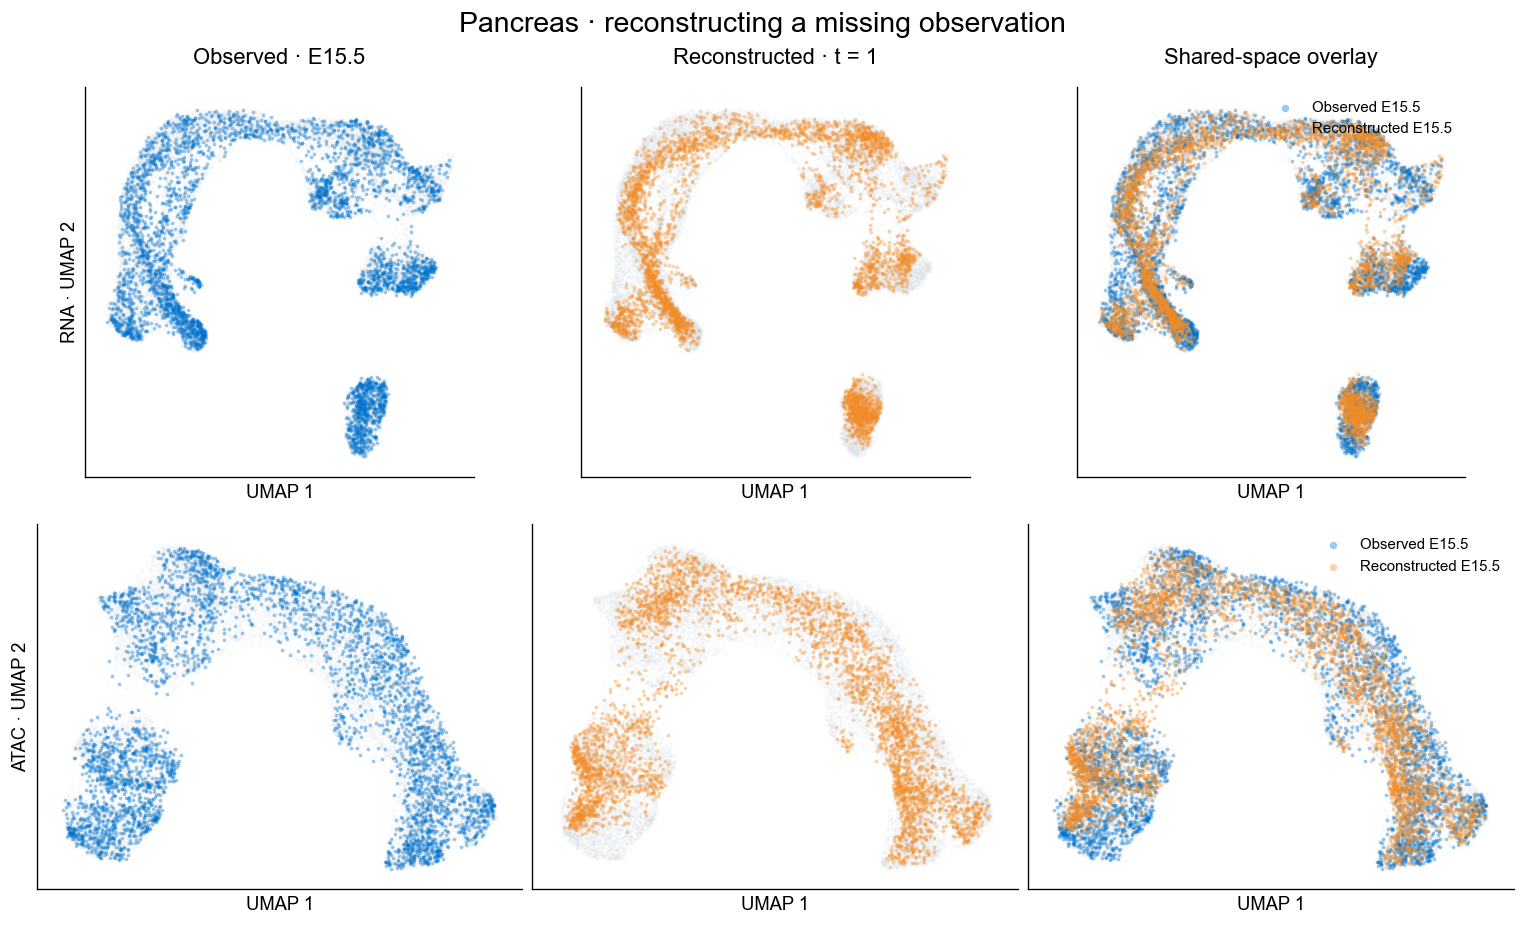

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12.6, 7.6), layout="constrained")
for row, modality in enumerate(("RNA", "ATAC")):
    coordinates = display_coordinates[modality]
    real = coordinates["observed"]
    predicted = coordinates["predicted"]
    plot_rng = np.random.default_rng(SEED)
    real = real[plot_rng.choice(len(real), size=min(4000, len(real)), replace=False)]
    combined = np.concatenate([coordinates["context"], predicted])
    low, high = combined.min(axis=0), combined.max(axis=0)
    pad = np.maximum((high - low) * 0.06, 0.1)
    for column, ax in enumerate(axes[row]):
        context = coordinates["context"]
        ax.scatter(context[:, 0], context[:, 1], s=2, c="#DDE3E8", alpha=0.2,
                   linewidths=0, rasterized=True)
        if column in (0, 2):
            ax.scatter(real[:, 0], real[:, 1], s=5, c="#0072CE", alpha=0.38,
                       linewidths=0, label="Observed E15.5", rasterized=True)
        if column in (1, 2):
            ax.scatter(predicted[:, 0], predicted[:, 1], s=5, c="#F28C28", alpha=0.38,
                       linewidths=0, label="Reconstructed E15.5", rasterized=True)
        ax.set(xlim=(low[0] - pad[0], high[0] + pad[0]), ylim=(low[1] - pad[1], high[1] + pad[1]),
               xlabel="UMAP 1", ylabel=f"{modality} · UMAP 2" if column == 0 else "")
        ax.set_aspect("equal", adjustable="box")
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(("Observed · E15.5", "Reconstructed · t = 1", "Shared-space overlay")[column], pad=14)
    axes[row, 2].legend(loc="upper right", frameon=False, markerscale=2, fontsize=9)
fig.suptitle("Pancreas · reconstructing a missing observation", fontsize=17)
fig.savefig(run_dir / "heldout_reconstruction_umap.png", dpi=200, bbox_inches="tight")
fig.savefig(run_dir / "heldout_reconstruction_umap.pdf", bbox_inches="tight")
plt.show()

## Measure distribution reconstruction outside UMAP

Use debiased Sinkhorn divergence with p = 2 in the normalized RNA/ATAC representations. Lower is better. All comparisons use 512 points per distribution and five deterministic repeats. The empirical observed-split score gives a sampling reference, not a universal threshold. The endpoint-mixture baseline puts equal probability on the two retained stages, without learning dynamics. Each row is a probability-distribution comparison; it does not evaluate population growth.

In [7]:
metric_rows = []
for modality, snapshots in (("RNA", observed.primary), ("ATAC", observed.secondary)):
    target = torch.tensor(heldout[modality])
    predicted = torch.tensor(reconstructed[modality])
    metric_rng = np.random.default_rng(SEED + 10)
    median_rows = metric_rng.choice(len(target), size=512, replace=False)
    distances = torch.pdist(target[median_rows])
    blur = max(0.05 * float(distances.median()), 1e-6)
    divergence = SamplesLoss("sinkhorn", p=2, blur=blur, debias=True, backend="tensorized")
    scores = {"Reconstruction": [], "Initial distribution": [], "Endpoint mixture": [], "Observed split": []}
    with torch.no_grad():
        for repeat in range(5):
            target_rows = metric_rng.choice(len(target), size=1024, replace=False)
            reference = target[target_rows[:512]]
            independent = target[target_rows[512:]]
            prediction_rows = metric_rng.choice(len(predicted), size=512, replace=False)
            initial = torch.tensor(snapshots[0][metric_rng.choice(len(snapshots[0]), size=512, replace=False)])
            mixture = torch.tensor(np.concatenate([
                snapshots[0][metric_rng.choice(len(snapshots[0]), size=256, replace=False)],
                snapshots[-1][metric_rng.choice(len(snapshots[-1]), size=256, replace=False)],
            ]))
            for name, sample in (("Reconstruction", predicted[prediction_rows]),
                                 ("Initial distribution", initial), ("Endpoint mixture", mixture),
                                 ("Observed split", independent)):
                scores[name].append(float(divergence(sample, reference)))
    for name, values in scores.items():
        metric_rows.append({"Modality": modality, "Comparison": name,
                            "Mean": float(np.mean(values)), "SD": float(np.std(values, ddof=1)),
                            "Blur": blur, "Points": 512, "Repeats": 5})
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(run_dir / "heldout_metrics.csv", index=False)
display(metrics.style.format({"Mean": "{:.5f}", "SD": "{:.5f}", "Blur": "{:.5f}"}))

,Modality,Comparison,Mean,SD,Blur,Points,Repeats
0,RNA,Reconstruction,0.37956,0.00974,0.12199,512,5
1,RNA,Initial distribution,0.63991,0.03310,0.12199,512,5
2,RNA,Endpoint mixture,0.39044,0.01051,0.12199,512,5
3,RNA,Observed split,0.32654,0.00482,0.12199,512,5
4,ATAC,Reconstruction,0.49141,0.01736,0.14310,512,5
5,ATAC,Initial distribution,0.77943,0.04277,0.14310,512,5
6,ATAC,Endpoint mixture,0.45730,0.01704,0.14310,512,5
7,ATAC,Observed split,0.38675,0.01236,0.14310,512,5


## Save the audit and inspect the result

The figures and scores are the outcome of this one short run, including any reconstruction error. No setting or checkpoint is selected using E15.5. A small UMAP separation is not proof of a good distribution match; use the representation-space scores as well. The existing all-data preprocessing remains fixed, so this experiment tests the exclusion of the middle stage from T and dynamics training, not exclusion from the original PCA/PoissonVI preprocessing.

In [8]:
audit = {
    "dataset": "pancreas", "seed": SEED, "heldout_stage": heldout_stage,
    "heldout_time": heldout_time, "training_stages": training.labels,
    "training_times": training.times.tolist(), "map_training_times": result.map_report["training_times"],
    "vector_field_iterations": checkpoint["iteration"], "training_seconds": training_seconds,
    "map_status": result.map_report["status"], "map_best_epoch": result.map_report["best_epoch"],
    "mode": "multimodal balanced", "prediction_particles": len(initial_rows),
    "preprocessing": "Frozen common all-data representations and scalar normalization; no second normalization.",
    "umap_fit_scope": "Retained observations only, one frozen projector per modality.",
    "evaluation_scope": "Held-out stage used only after training for display and distribution scores.",
    "source_sha256": {name: hashlib.sha256((data_dir / name).read_bytes()).hexdigest()
                       for name in ("rna.h5ad", "atac.h5ad")},
    "config": config.to_dict(), "map_config": map_config.to_dict(),
    "metrics": metrics.to_dict(orient="records"),
}
(run_dir / "heldout_report.json").write_text(json.dumps(audit, indent=2) + "\n")
print("UMAP figure:", run_dir / "heldout_reconstruction_umap.png")
print("Scores:", run_dir / "heldout_metrics.csv")
print("Audit:", run_dir / "heldout_report.json")

UMAP figure: /Users/jingfeng/local/project/COATI/outputs/pancreas-heldout-1000-20261012T175116530337Z/heldout_reconstruction_umap.png
Scores: /Users/jingfeng/local/project/COATI/outputs/pancreas-heldout-1000-20261012T175116530337Z/heldout_metrics.csv
Audit: /Users/jingfeng/local/project/COATI/outputs/pancreas-heldout-1000-20261012T175116530337Z/heldout_report.json


## What this saved run shows

The 1,000-step run covers the main held-out regions in both display embeddings, with visible local density differences. In the original model space, reconstruction scores were **0.3796 (RNA)** and **0.4914 (ATAC)**, compared with **0.6399** and **0.7794** for the initial distribution. The endpoint-mixture scores were **0.3904** and **0.4573**: RNA reconstruction is only slightly better, while ATAC reconstruction is worse than that simple baseline. These five subsampling repeats describe this one seed; they are not independent training replicates.

This is a runnable distribution-reconstruction example, not evidence of convergence or superiority over external methods. Increase training or compare other modes in a separately named experiment; do not choose settings using this held-out stage.